In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xtrack as xt
import xcoll as xc
import xpart as xp
import xobjects as xo
import json
import sys
sys.path.insert(0, '/Users/lisepauwels/phd/code/sps-offmom-scans/')
from xjson import NumpyFriendlyEncoder

from scipy import stats

# Tracking and saving particles and impact table

In [6]:
xcoll_version = xc.__version__
# coll = xc.EverestBlock(length=1.83, material=xc.materials.CarbonFibreCarbon if xcoll_version == '0.10.1' else xc.materials.Carbon) #, emittance=3.5e-6)
coll = xc.EverestBlock(length=1.83, material=xc.materials.Beryllium) #, emittance=3.5e-6)
num_part = int(1_000_000)
x_init   = np.random.normal(loc=0, scale=1e-3, size=num_part)
px_init  = np.random.normal(loc=0, scale=1e-6, size=num_part)
py_init  = np.random.normal(loc=0, scale=1e-6, size=num_part)
y_init   = np.random.normal(loc=0, scale=1e-3, size=num_part)
part = xp.Particles(x=x_init, px=px_init, y=y_init, py=py_init, delta=0, p0c=25920000000.0)

impacts_coll = xc.InteractionRecord.start(elements=[coll], names='TCSM')
part_init = part.copy()
coll.track(part)
part.sort(interleave_lost_particles=True)
# impacts_coll.stop()
impacts_coll.to_pandas().to_csv(f'impacts_coll_{xcoll_version}_ber.csv', index=False)
with open(f'part_coll_{xcoll_version}_ber.json', 'w') as f:
    json.dump(part.to_dict(), f, indent=4, cls=NumpyFriendlyEncoder)

KeyboardInterrupt: 

# Loading the different versions and comparing

## Impact table

In [ ]:
df = pd.read_csv('impacts_coll_0.10.1.csv')
df2 = pd.read_csv('impacts_coll_0.6.8.csv')

interaction_types, counts = np.unique(np.array(df.interaction_type), return_counts=True)
print('xcoll 0.10.1:')
print(interaction_types)
print(counts)
interaction_types2, counts2 = np.unique(np.array(df2.interaction_type), return_counts=True)
print('xcoll 0.6.8:')
print(interaction_types2)
print(counts2)

xcoll 0.10.1:
['Absorbed' 'Coulomb' 'Multiple Coulomb Scattering' 'PN Elastic'
 'PP Elastic' 'Single Diffractive']
[339992    115 505691  80672  42651  30879]
xcoll 0.6.8:
['Absorbed' 'Coulomb' 'Multiple Coulomb Scattering' 'PN Elastic'
 'PP Elastic' 'Single Diffractive']
[339853    121 505762  80923  42354  30987]


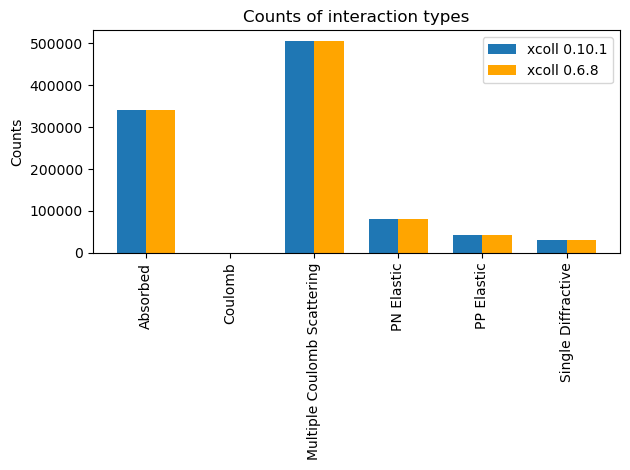

In [ ]:
pos = np.arange(len(interaction_types))  # assumes both lists have same labels in same order
width = 0.35

fig, ax = plt.subplots()
ax.bar(pos - width/2, counts, width, label='xcoll 0.10.1')
ax.bar(pos + width/2, counts2, width, color='orange', label='xcoll 0.6.8')

ax.set_ylabel('Counts')
ax.set_title('Counts of interaction types')
ax.set_xticks(pos)
ax.set_xticklabels(interaction_types, rotation=90)
ax.legend()
plt.tight_layout()
plt.show()

## Particle distribution

In [ ]:
part = xp.Particles.from_dict(json.load(open('part_coll_0.10.1.json', 'r')))
part_v2 = xp.Particles.from_dict(json.load(open('part_coll_0.10.1_2.json', 'r')))
part2 = xp.Particles.from_dict(json.load(open('part_coll_0.6.8.json', 'r')))
part2_v2 = xp.Particles.from_dict(json.load(open('part_coll_0.6.8_2.json', 'r')))

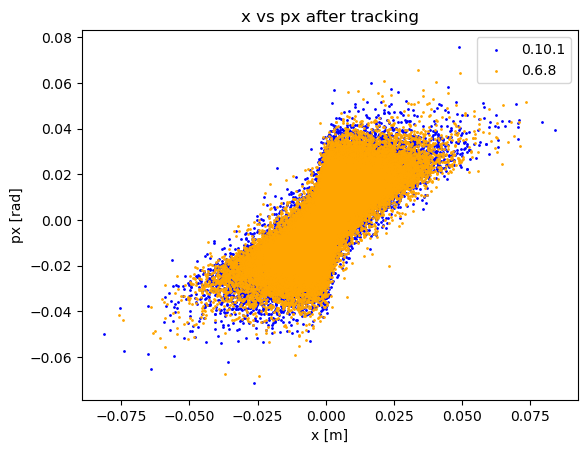

In [ ]:
fig, ax = plt.subplots()
ax.scatter(part.x, part.px, s=1, label='0.10.1', color='blue')
ax.scatter(part_v2.x, part_v2.px, s=1, color='blue')
ax.scatter(part2.x, part2.px, s=1, label='0.6.8', color='orange')
ax.scatter(part2_v2.x, part2_v2.px, s=1, color='orange')
ax.set_xlabel('x [m]')
ax.set_ylabel('px [rad]')
ax.set_title('x vs px after tracking')
ax.legend()

In [ ]:
print('x:')
print('Maximum:', np.max(part.x), np.max(part2.x))
print('Minimum:', np.min(part.x), np.min(part2.x))
print('Mean:', np.mean(part.x), np.mean(part2.x))
print('Std:', np.std(part.x), np.std(part2.x))

print('Percentiles 25-50-75:', np.percentile(part.x, [25, 50, 75]), np.percentile(part2.x, [25, 50, 75]))
print('Percentiles 99:', np.percentile(part.x, 99), np.percentile(part2.x, 99))
print('mad:', stats.median_abs_deviation(part.x), stats.median_abs_deviation(part2.x))
print(' ')
print('px:')
print('Maximum:', np.max(part.px), np.max(part2.px))
print('Minimum:', np.min(part.px), np.min(part2.px))
print('Mean:', np.mean(part.px), np.mean(part2.px))
print('Std:', np.std(part.px), np.std(part2.px))
print('Percentiles 25-50-75:', np.percentile(part.px, [25, 50, 75]), np.percentile(part2.px, [25, 50, 75]))
print('Percentiles 99:', np.percentile(part.px, 99), np.percentile(part2.px, 99))
print('mad:', stats.median_abs_deviation(part.px), stats.median_abs_deviation(part2.px))

x:
Maximum: 0.0841294938228242 0.07338239449101837
Minimum: -0.06534569874641975 -0.0757240785277366
Mean: -3.185330542595266e-06 9.966102893669554e-08
Std: 0.0028826713632723582 0.0028744968414454726
Percentiles 25-50-75: [-8.45895275e-04 -4.73275640e-07  8.44144133e-04] [-8.46636901e-04 -2.11018837e-06  8.41768852e-04]
Percentiles 99: 0.009031315290358971 0.009027860550083795
mad: 0.0008450650687799582 0.000844226493746603
 
px:
Maximum: 0.05813683664031868 0.06067203834385993
Minimum: -0.0712897443021574 -0.059107979625814974
Mean: -5.886377580583069e-06 1.4614821183639688e-06
Std: 0.004276487958587523 0.004289713861815239
Percentiles 25-50-75: [-5.25226814e-04 -4.87447018e-07  5.22410812e-04] [-5.24204128e-04  4.19177933e-07  5.25486299e-04]
Percentiles 99: 0.014923071980052759 0.014953826349475318
mad: 0.000523813075879854 0.0005248678007765152


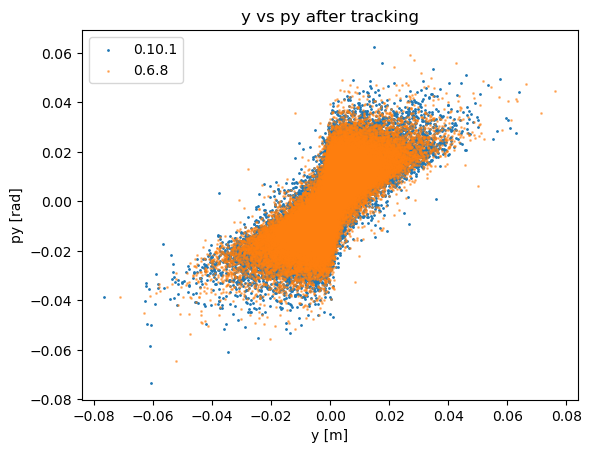

In [ ]:
fig, ax = plt.subplots()
ax.scatter(part.y, part.py, s=1, label='0.10.1')
ax.scatter(part2.y, part2.py, s=1, label='0.6.8', alpha=0.5)
ax.set_xlabel('y [m]')
ax.set_ylabel('py [rad]')
ax.set_title('y vs py after tracking')
ax.legend()

In [ ]:
print('y:')
print('Maximum:', np.max(part.y), np.max(part2.y))
print('Minimum:', np.min(part.y), np.min(part2.y))
print('Mean:', np.mean(part.y), np.mean(part2.y))
print('Std:', np.std(part.y), np.std(part2.y))

print('Percentiles 25-50-75:', np.percentile(part.y, [25, 50, 75]), np.percentile(part2.y, [25, 50, 75]))
print('Percentiles 99:', np.percentile(part.y, 99), np.percentile(part2.y, 99))
print('mad:', stats.median_abs_deviation(part.y), stats.median_abs_deviation(part2.y))
print(' ')
print('py:')
print('Maximum:', np.max(part.py), np.max(part2.py))
print('Minimum:', np.min(part.py), np.min(part2.py))
print('Mean:', np.mean(part.py), np.mean(part2.py))
print('Std:', np.std(part.py), np.std(part2.py))
print('Percentiles 25-50-75:', np.percentile(part.py, [25, 50, 75]), np.percentile(part2.py, [25, 50, 75]))
print('Percentiles 99:', np.percentile(part.py, 99), np.percentile(part2.py, 99))
print('mad:', stats.median_abs_deviation(part.py), stats.median_abs_deviation(part2.py))

y:
Maximum: 0.07217233373345475 0.07628132534092363
Minimum: -0.07328022058648773 -0.07129993492952746
Mean: 5.240253683100431e-07 -4.1353171502791115e-06
Std: 0.0028691904621410956 0.0028783331507428044
Percentiles 25-50-75: [-8.45818855e-04 -1.52743393e-06  8.42108738e-04] [-8.46242405e-04 -1.22227697e-06  8.42708003e-04]
Percentiles 99: 0.009060151683327074 0.008966997571001726
mad: 0.0008439738457306591 0.0008444052692816668
 
py:
Maximum: 0.05718169750159196 0.059045052497512164
Minimum: -0.06398331484132994 -0.06463684973901099
Mean: -3.73250797416903e-06 -3.1255765888244027e-06
Std: 0.004266551669609224 0.004280952012407285
Percentiles 25-50-75: [-5.22817059e-04 -5.11199523e-07  5.21513992e-04] [-5.26098386e-04  8.97419251e-08  5.28169728e-04]
Percentiles 99: 0.014872504779343385 0.01487493227275957
mad: 0.0005222088704780628 0.0005271724964593346


### Mogr

In [ ]:
part = xp.Particles.from_dict(json.load(open('part_coll_0.10.1_Mogr.json', 'r')))
part2 = xp.Particles.from_dict(json.load(open('part_coll_0.6.8_Mogr.json', 'r')))

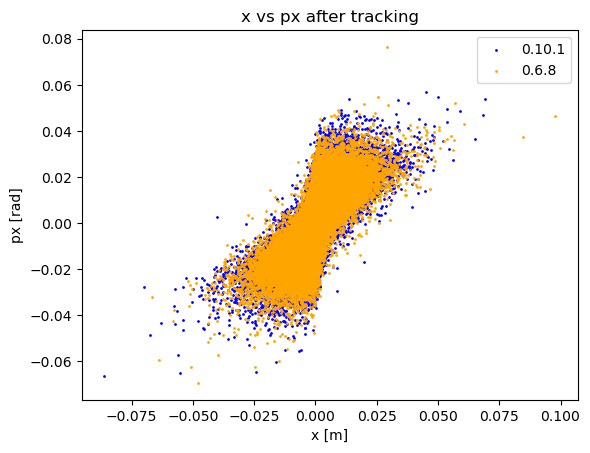

In [ ]:
fig, ax = plt.subplots()
ax.scatter(part.x, part.px, s=1, label='0.10.1', color='blue')
ax.scatter(part2.x, part2.px, s=1, label='0.6.8', color='orange')
ax.set_xlabel('x [m]')
ax.set_ylabel('px [rad]')
ax.set_title('x vs px after tracking')
ax.legend()

In [ ]:
print('x:')
print('Maximum:', np.max(part.x), np.max(part2.x))
print('Minimum:', np.min(part.x), np.min(part2.x))
print('Mean:', np.mean(part.x), np.mean(part2.x))
print('Std:', np.std(part.x), np.std(part2.x))

print('Percentiles 25-50-75:', np.percentile(part.x, [25, 50, 75]), np.percentile(part2.x, [25, 50, 75]))
print('Percentiles 99:', np.percentile(part.x, 99), np.percentile(part2.x, 99))
print('mad:', stats.median_abs_deviation(part.x), stats.median_abs_deviation(part2.x))
print(' ')
print('px:')
print('Maximum:', np.max(part.px), np.max(part2.px))
print('Minimum:', np.min(part.px), np.min(part2.px))
print('Mean:', np.mean(part.px), np.mean(part2.px))
print('Std:', np.std(part.px), np.std(part2.px))
print('Percentiles 25-50-75:', np.percentile(part.px, [25, 50, 75]), np.percentile(part2.px, [25, 50, 75]))
print('Percentiles 99:', np.percentile(part.px, 99), np.percentile(part2.px, 99))
print('mad:', stats.median_abs_deviation(part.px), stats.median_abs_deviation(part2.px))

x:
Maximum: 0.06910983231900039 0.09788749182251805
Minimum: -0.08606042363532262 -0.06656396813733978
Mean: -2.4125614671678e-06 -2.5892316650823207e-06
Std: 0.002371337161062155 0.0023858179523425812
Percentiles 25-50-75: [-8.15791090e-04 -2.05519699e-06  8.12734717e-04] [-8.16542897e-04 -1.86289532e-06  8.11710799e-04]
Percentiles 99: 0.00690352926234127 0.0069941106437005
mad: 0.0008142340788113373 0.0008141204302704018
 
px:
Maximum: 0.05690318457040425 0.07643503355335621
Minimum: -0.06631939076825677 -0.06938164904726402
Mean: 2.1912478246129835e-06 -1.370293664881103e-06
Std: 0.004325081720012133 0.004340599427112886
Percentiles 25-50-75: [-6.62736755e-04  8.50542090e-07  6.63109827e-04] [-6.46731639e-04 -3.67240698e-08  6.43810561e-04]
Percentiles 99: 0.014981244547742632 0.015092608894506391
mad: 0.0006629035227369069 0.0006453544888477229


### Beryllium

In [ ]:
part = xp.Particles.from_dict(json.load(open('part_coll_0.10.1_ber.json', 'r')))
part2 = xp.Particles.from_dict(json.load(open('part_coll_0.6.8_ber.json', 'r')))

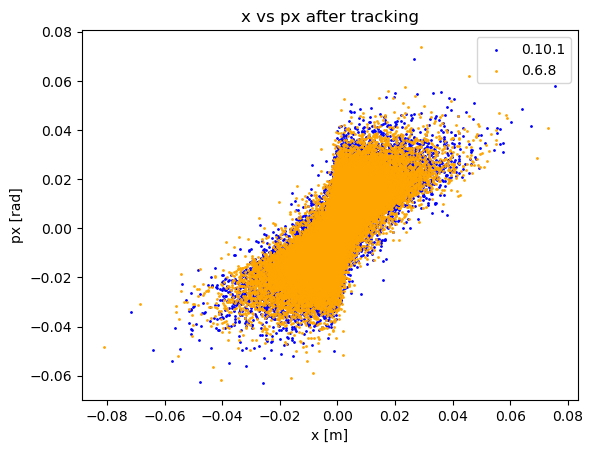

In [ ]:
fig, ax = plt.subplots()
ax.scatter(part.x, part.px, s=1, label='0.10.1', color='blue')
ax.scatter(part2.x, part2.px, s=1, label='0.6.8', color='orange')
ax.set_xlabel('x [m]')
ax.set_ylabel('px [rad]')
ax.set_title('x vs px after tracking')
ax.legend()

In [ ]:
print('x:')
print('Maximum:', np.max(part.x), np.max(part2.x))
print('Minimum:', np.min(part.x), np.min(part2.x))
print('Mean:', np.mean(part.x), np.mean(part2.x))
print('Std:', np.std(part.x), np.std(part2.x))

print('Percentiles 25-50-75:', np.percentile(part.x, [25, 50, 75]), np.percentile(part2.x, [25, 50, 75]))
print('Percentiles 99:', np.percentile(part.x, 99), np.percentile(part2.x, 99))
print('mad:', stats.median_abs_deviation(part.x), stats.median_abs_deviation(part2.x))
print(' ')
print('px:')
print('Maximum:', np.max(part.px), np.max(part2.px))
print('Minimum:', np.min(part.px), np.min(part2.px))
print('Mean:', np.mean(part.px), np.mean(part2.px))
print('Std:', np.std(part.px), np.std(part2.px))
print('Percentiles 25-50-75:', np.percentile(part.px, [25, 50, 75]), np.percentile(part2.px, [25, 50, 75]))
print('Percentiles 99:', np.percentile(part.px, 99), np.percentile(part2.px, 99))
print('mad:', stats.median_abs_deviation(part.px), stats.median_abs_deviation(part2.px))

x:
Maximum: 0.07565538011225036 0.07324676228294168
Minimum: -0.07181701667694657 -0.0809199882957942
Mean: 7.685875120044657e-07 -1.4716926490143453e-06
Std: 0.002625467519294328 0.00264361866007237
Percentiles 25-50-75: [-8.13868812e-04 -2.28257719e-06  8.11094748e-04] [-8.11742922e-04 -1.14198236e-06  8.09497125e-04]
Percentiles 99: 0.008137417378235446 0.008083476332551038
mad: 0.0008124103667532785 0.0008106194984038633
 
px:
Maximum: 0.06869299135394986 0.07379152843005525
Minimum: -0.06295005856895383 -0.06167616314970866
Mean: 3.188089451510747e-06 1.5360724430630104e-06
Std: 0.004388289285894906 0.004396433453996427
Percentiles 25-50-75: [-3.94344569e-04  7.41399497e-08  3.95282804e-04] [-3.94475704e-04 -1.42991858e-07  3.94308597e-04]
Percentiles 99: 0.015480392387369415 0.015462551443274295
mad: 0.0003948610029207382 0.0003943939482093568


There doesn't seem to be a huge difference. Significant shift in x that is not present in mogr but is there in beryllium

# Loading lines for different versions

In [7]:
print(xc.__version__)
line = xt.load('/Users/lisepauwels/phd/code/sps-crab-cavities/sps_with_aperture_inj_q20_beam_sagitta4.json')
env = line.env
env['vttm.52002.b_aper']

0.6.8


Loading line from dict: 100%|██████████| 36381/36381 [00:00<00:00, 51346.50it/s]

Done loading line from dict.           


View of LimitEllipse(a=0.076, b=0.0208)

In [2]:
print(xc.__version__)
line = xt.load('/Users/lisepauwels/phd/code/sps-crab-cavities/sps_with_aperture_inj_q20_beam_sagitta4.json')
env = line.env
env['vttm.52002.b_aper']

0.10.1


Loading line from dict:   0%|          | 0/36381 [00:00<?, ?it/s]

/Users/lisepauwels/Xsuite/xtrack/xtrack/beam_elements/elements.py:793: FutureWarning: `lag` (in degrees) is deprecated and will be removed in a future version. Please use `phase` (in radians) instead. If you see this warning while loading a saved line from a previous version of Xsuite, please regenerate the line with the current version to use phase instead of lag. Note that if both `lag` and `phase` are set, the effect is the sum of the two,  with `lag` converted to radians.  This deprecation is part of the interface cleanup in view of the 1.0 release.
  self.lag = lag
/Users/lisepauwels/Xsuite/xtrack/xtrack/beam_elements/elements.py:3783: FutureWarning: `pn` (in degrees) is deprecated and will be removed in a future version. Please use `phase_n` (in radians) instead. Note that if both `pn` and `phase_n` are set, the effect is the sum of the two with `pn` converted to radians.
  self._warn_if_deprecated_phase_is_nonzero(pn, 'pn', 'phase_n')
/Users/lisepauwels/Xsuite/xtrack/xtrack/beam

Done loading line from dict.           


View of LimitEllipse(a=0.076, b=0.0208)

Well clearly it is not the aperture (just in case anyone was doubting it)